In [1]:
import os
from tqdm import tqdm

import numpy as np
from numpy import cos, cosh, exp
import matplotlib.pyplot as plt
import matplotlib
import mlflow
import torch as th
from scipy.stats import norm

from ml.bayes import compute_bayes_posterior

# Set matplotlib to use TeX for rendering
matplotlib.rcParams.update({"font.size": 16})
plt.rcParams["figure.dpi"] = 125 #200  # set fig resolution

plt.rcParams.update({"text.usetex": True, "font.family": "Helvetica"})

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false" # Disable MLflow artifacts progress bar

In [2]:
def wait_time_pdf(tau: float, omega: float, delta: float) -> float:
    """
    Calculates the waiting time distribution of a coherently
    driven two-level system based on omega and delta. Code adapted from:

    We set \gamma = 1 as in the paper.

    Args:
        tau: Time delay.
        omega: Rabi frequency.
        delta: Qubit-drive detuning.

    Returns:
        float: Probability density, w(tau).
    """

    R = np.sqrt((1 + 4 * (delta**2 + 4 * omega**2)) ** 2 - 64 * omega**2)
    w_tau = 8 * exp(-tau / 2) * omega**2 / R

    A = np.sqrt(-64 * omega**2 + (1 + 4 * delta**2 + 16 * omega**2) ** 2)
    sum_term1 = -cos(
        tau * np.sqrt(-1 + 4 * delta**2 + 16 * omega**2 + A) / (2 * np.sqrt(2))
    )
    sum_term2 = cosh(
        tau * np.sqrt(1 - 4 * delta**2 - 16 * omega**2 + A) / (2 * np.sqrt(2))
    )

    w_tau *= sum_term1 + sum_term2

    return w_tau

In [3]:
# pdfs = []
# taus = np.linspace(0, 20, 500)
# deltas = [0.0, 0.2, 0.5, 1, 2]
# omegas = 1.0
# for delta in deltas:
#     pdfs.append(wait_time_pdf(tau=taus, omega=omega, delta=delta))


# for i, delta in enumerate(deltas):
#     #plt.xscale("log")
#     #plt.ylim(0, 0.58)
#     plt.plot(taus, pdfs[i], label=rf"$\Delta={delta}$")

# plt.xlabel(r"$\tau/\gamma$", fontsize=20)
# plt.ylabel(rf"$P(\tau|\Omega={omega}, \Delta)$", fontsize=20)
# plt.legend(frameon=False, loc="upper right");


In [4]:
def bhattacharyya_coefficient_numpy(hist1, hist2):
    # Normalize the histograms to make them probability distributions
    # Ensure they are numpy arrays
    #hist1 = np.array(hist1)
    #hist2 = np.array(hist2)

    # Check if the sum is zero to prevent division by zero
    sum1 = np.sum(hist1)
    sum2 = np.sum(hist2)
    if sum1 == 0 or sum2 == 0:
        return 0 # Or handle as appropriate for your use case

    p = hist1 / sum1
    q = hist2 / sum2
    
    # Compute the coefficient using the formula
    # np.sqrt() is applied element-wise
    # np.sum() sums the resulting elements
    coefficient = np.sum(np.sqrt(p * q))
    return coefficient

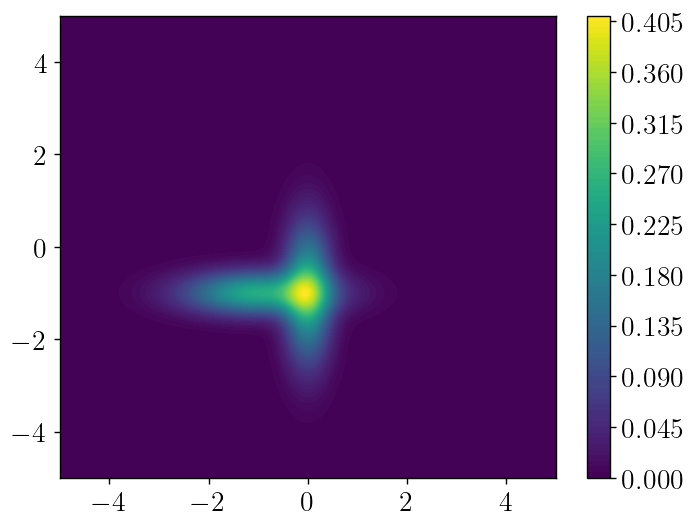

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

# grid
x = np.linspace(-5, 5, 200)
y = np.linspace(-5, 5, 200)
X, Y = np.meshgrid(x, y)
pos = np.dstack((X, Y))

# two Gaussians
g1 = multivariate_normal(mean=[-1, -1], cov=[[1, 0], 
                                             [0, .1]])
g2 = multivariate_normal(mean=[0, -1], cov=[[.1, 0], 
                                           [0, 1]])

# mixture (equal weights)
Z = 0.5 * g1.pdf(pos) + 0.5 * g2.pdf(pos)

# plot
plt.contourf(X, Y, Z, levels=100)
plt.colorbar()
plt.show()

In [32]:
import numpy as np
from ml.bayes import compute_likelihood_analytical

def compute_bayes_posterior_2d(
    data: list[float],
    delta_vals: np.ndarray,
    omega_vals: np.ndarray,
    prior_delta_min: float = 0.0,
    prior_delta_max: float = 5.0,
    prior_omega_min: float = 0.0,
    prior_omega_max: float = 5.0,
    gamma: float = 1.0,
):
    """
    Compute Bayesian posterior P(Delta, Omega | D) on a grid.

    Returns
    -------
    posterior : np.ndarray shape (len(omega_vals), len(delta_vals))
    """

    D, O = np.meshgrid(delta_vals, omega_vals)

    likelihood = np.zeros_like(D)

    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            likelihood[i, j] = compute_likelihood_analytical(
                D[i, j], data, gamma, O[i, j]
            )

    # uniform prior
    prior = np.where(
        (D >= prior_delta_min) & (D <= prior_delta_max) &
        (O >= prior_omega_min) & (O <= prior_omega_max),
        1.0 / ((prior_delta_max - prior_delta_min) *
               (prior_omega_max - prior_omega_min)),
        0.0,
    )

    posterior = likelihood * prior

    # normalize 2D integral
    #Z = np.trapz(np.trapz(posterior, delta_vals, axis=1), omega_vals)
    dx = delta_vals[1] - delta_vals[0]
    dy = omega_vals[1] - omega_vals[0]

    Z = posterior.sum() * dx * dy
    if Z > 0:
        posterior /= Z
    else:
        print("Warning")

    return posterior

In [8]:
label = 19
sample = 1

X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)[label, sample]

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    ).reshape(-1, 1)[label][0]

print(X_test.shape)
print(y_test)

(48,)
1.0230769230769232


Warning
nan


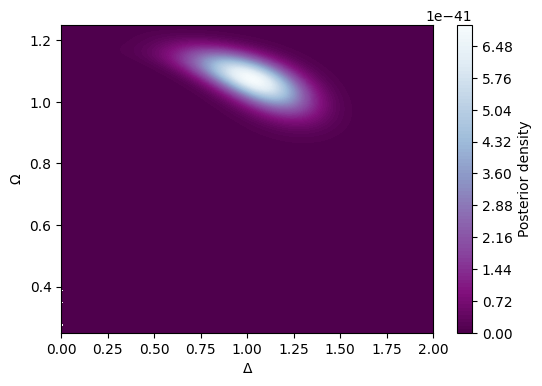

In [33]:
import matplotlib.pyplot as plt

# parameter grids
delta_vals = np.linspace(0, 2, 200)
omega_vals = np.linspace(0.25, 1.25, 200)

posterior = compute_bayes_posterior_2d(
    data=X_test,
    delta_vals=delta_vals,
    omega_vals=omega_vals,
    prior_delta_min=0,
    prior_delta_max=2.1,
    prior_omega_min=0.25,
    prior_omega_max=1.25,
    gamma=1.0,
)
print(posterior.max())
plt.figure(figsize=(6,4))
plt.contourf(delta_vals, omega_vals, posterior, levels=100, cmap=plt.get_cmap("BuPu").reversed())
plt.xlabel(r"$\Delta$")
plt.ylabel(r"$\Omega$")
plt.colorbar(label="Posterior density")
plt.show()

In [24]:
print(posterior)

[[           nan 1.45681987e-57 1.42457622e-57 ... 1.04185648e-83
  5.48724156e-84 2.89135110e-84]
 [5.89751428e-56 5.89458893e-56 5.87953124e-56 ... 4.23091944e-81
  2.24781695e-81 1.19395239e-81]
 [           nan 1.01965425e-54 1.06557778e-54 ... 1.09369625e-78
  5.86265598e-79 3.13956993e-79]
 ...
 [2.38835540e-72 2.61139508e-72 3.36850643e-72 ... 2.70857203e-57
  3.88355274e-57 5.54681088e-57]
 [1.96295405e-71 2.14602590e-71 2.75687776e-71 ... 5.70082002e-57
  8.15991070e-57 1.16287917e-56]
 [8.81481017e-70 8.93297946e-70 9.29446451e-70 ... 1.22289635e-56
  1.74235427e-56 2.46981041e-56]]


In [17]:
model_uri = "runs:/4c31804a77724d85aa3c2d95c1d3db82/ensemble_model"
tls_ensemble_model = mlflow.pytorch.load_model(model_uri=model_uri)

true_delta = y_test
print(f"True delta: {true_delta}")
samp = th.tensor(X_test, dtype=th.float32).unsqueeze(0)
means = [model(samp)[0][0].item() for model in tls_ensemble_model]
stds = [np.sqrt(model(samp)[0][1].item()) for model in tls_ensemble_model]
vars = [model(samp)[0][1].item() for model in tls_ensemble_model]
print(f"Means: {means}")
print(f"Vars: {vars}")
print(f"Stds: {stds}")

True delta: 1.0230769230769232
Means: [1.1387523412704468, 1.1351605653762817, 1.136767864227295, 1.129865050315857, 1.1496189832687378, 1.1449384689331055, 1.2291829586029053, 1.0890166759490967, 1.1479811668395996, 1.1737151145935059]
Vars: [0.02633868157863617, 0.027105240151286125, 0.027727406471967697, 0.028574854135513306, 0.028165146708488464, 0.027203748002648354, 0.031729795038700104, 0.029231207445263863, 0.029022015631198883, 0.030133243650197983]
Stds: [0.16229196399894905, 0.16463669138829937, 0.16651548418080434, 0.1690409835972132, 0.16782474998786223, 0.16493558743536324, 0.1781285913004987, 0.1709713644013636, 0.17035849151480206, 0.17358929589752353]


In [18]:
# X range
x = np.linspace(-2, 5.5, 1000)

bayes_y = compute_bayes_posterior(X_test, x_vals=x, prior_delta_min=0, prior_delta_max=5, n_grid=500, omega=1, gamma=1)

Fidelity is 0.9869.


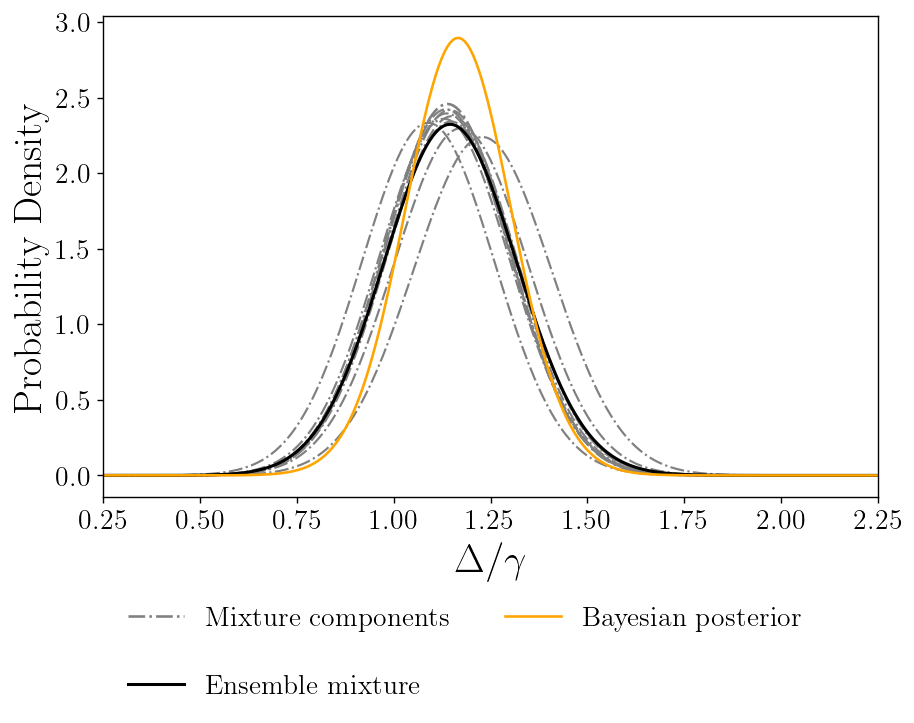

In [19]:
# Parameters for the Gaussians
means = np.array(means)
stds = np.array(stds)

# Compute each Gaussian PDF
pdfs = [norm.pdf(x, loc=m, scale=s) for m, s in zip(means, stds)]

# Plot
plt.figure(figsize=(8, 5))
for i, pdf in enumerate(pdfs):
    if i == 0:
        plt.plot(x, pdf, '-.', label=r'\textrm{Mixture components}', color="gray")
    else:
        plt.plot(x, pdf, '-.', linewidth=1.25, color="gray")

# Total mixture
weight = 1/len(tls_ensemble_model.models) # mixture weights (should sum to 1)
weights = [weight for _ in pdfs]
pdfs = [weight*pdf for pdf in pdfs]
mixture_pdf = np.sum(pdfs, axis=0)
mixture_mean = np.dot(weights, means)
mixture_pdf_at_mean = sum(w * norm.pdf(mixture_mean, loc=m, scale=s) 
                          for w, m, s in zip(weights, means, stds))


plt.plot(x, mixture_pdf, linewidth=1.75, label=r'\textrm{Ensemble mixture}', color='black')
# plt.scatter(mixture_mean, mixture_pdf_at_mean, color='red', marker="o", zorder=5, s=50, label=r'\textrm{Mixture mean}')
# plt.axvline(x=true_delta, color="black", linestyle='--', linewidth=1, label=r"\textrm{True} $\Delta$")

bc = bhattacharyya_coefficient_numpy(bayes_y, mixture_pdf)
print(f"Fidelity is {bc:.4f}.")

plt.plot(x, bayes_y, label=r"\textrm{Bayesian posterior}", color="orange")
plt.xlim(0.25, 2.25)
#plt.yscale('log')

plt.xlabel(r'$\Delta/\gamma$', fontsize=23)
plt.ylabel(r'\textrm{Probability Density}', fontsize=23)
plt.legend(fancybox=True, ncol=2, frameon=False, loc="upper left", bbox_to_anchor=(0.0, -0.175), labelspacing=1.5);
#plt.tight_layout()
plt.savefig("figures/posterior_example.png", dpi=300, bbox_inches='tight')

In [20]:
X_test = np.load(
    "../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)

y_test = np.load(
        "../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
    )

In [21]:
os.path.exists("ensemble_tls_fids.npy")

True

In [22]:
if os.path.exists("ensemble_tls_fids.npy"):
   avg_fids = np.load("ensemble_tls_fids.npy").tolist() 
   
else:
    num_components = len(tls_ensemble_model.models)
    weights = [1/num_components]*num_components  # mixture weights (should sum to 1)
    avg_fids = []
    x = np.linspace(-2, 5.5, 1000)

    for i, delta in enumerate(tqdm(y_test)):
        fids = []
        
        for traj in X_test[i, :100]:

            bayes_pdf = compute_bayes_posterior(traj, x_vals=x, prior_delta_min=0, prior_delta_max=5, n_grid=500, omega=1, gamma=1)
            samp = th.tensor(traj, dtype=th.float32).unsqueeze(0)
            means = [model(samp)[0][0].item() for model in tls_ensemble_model]
            stds = [np.sqrt(model(samp)[0][1].item()) for model in tls_ensemble_model]
            means = np.array(means)
            stds = np.array(stds)   

            # Compute each Gaussian PDF
            ensemble_pdfs = np.array([norm.pdf(x, loc=m, scale=s) for m, s in zip(means, stds)])
            mixture_pdf = np.sum(ensemble_pdfs/weights[0], axis=0)

            F = bhattacharyya_coefficient_numpy(bayes_pdf, mixture_pdf)
            fids.append(F)
        
        avg_fids.append(np.mean(fids))

In [23]:
# np.save('ensemble_tls_fids.npy', np.array(avg_fids))

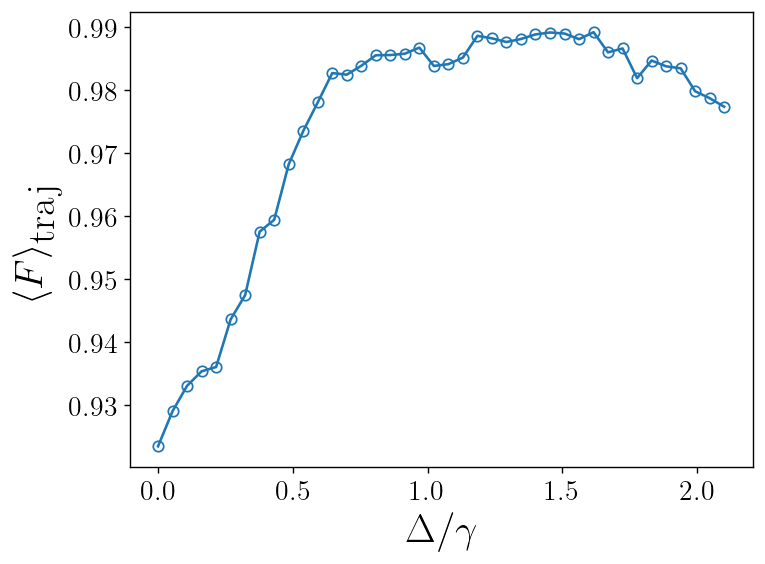

In [24]:
plt.xlabel(r'$\Delta/\gamma$', fontsize=23)
plt.ylabel(r'$\langle F\rangle_{\textrm{traj}}$', fontsize=23)
plt.plot(y_test, avg_fids, marker="o", markerfacecolor="none", linestyle="-");
plt.tight_layout()
plt.savefig("figures/ensemble_posterior_fid.png", dpi=300); 